<a href="https://colab.research.google.com/github/AyaanMahajan/econ3916/blob/main/PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECON 3916 — Problem Set 4
## The Model That Fit Too Well

**Ayaan Mahajan**  
**Role: Analyst, Revenue Forecasting**

The goal is to reproduce a model that looks very strong in sample, figure out why it fails on the stores that matter most, and replace it with a more honest validation setup.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold, learning_curve, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import t

rng = np.random.default_rng(3916)

# Phase 1 — Reproduce the 0.94

## Step 1.1 — Build the store panel

I simulate 450 stores. Revenue depends on floor area, foot traffic, local median income, and years open. Several other columns are noise. I also create one feature that is almost a linear combination of floor area and foot traffic.

The floor-area effect gets flatter after 10,000 square feet, so the biggest stores do not keep gaining revenue at the same rate. The error spread also grows with store size.

In [2]:
n = 450

floor_area = np.clip(
    rng.lognormal(mean=np.log(8000), sigma=0.55, size=n),
    1500, 28000
)

foot_traffic = np.clip(
    6000 + 0.55 * floor_area + rng.normal(0, 4500, n),
    1500, None
)

median_income = np.clip(rng.normal(85000, 18000, n), 35000, 160000)
years_open = rng.integers(1, 31, n)

# Irrelevant predictors
parking_spaces = rng.normal(90, 25, n)
manager_tenure = rng.uniform(0.5, 12, n)
competitors = rng.poisson(4, n)
promo_index = rng.normal(0, 1, n)
weather_index = rng.normal(0, 1, n)
store_age = rng.uniform(1, 15, n)
local_growth = rng.normal(0.02, 0.03, n)

# Near-collinear feature
size_traffic_index = (
    0.90 * floor_area
    + 0.35 * foot_traffic
    + rng.normal(0, 500, n)
)

# Floor area helps revenue, but much less after 10,000 sq ft
floor_effect = (
    0.12 * np.minimum(floor_area, 10000)
    + 0.05 * np.maximum(floor_area - 10000, 0)
)

true_mean = (
    150
    + 0.020 * foot_traffic
    + 0.0015 * median_income
    + 3.2 * years_open
    + floor_effect
)

# Larger stores have larger error variance
noise_sd = 25 + 0.0035 * floor_area
noise_rng = np.random.default_rng(999)

revenue = true_mean + noise_rng.normal(0, noise_sd * 0.9, n)

stores = pd.DataFrame({
    "floor_area": floor_area,
    "foot_traffic": foot_traffic,
    "median_income": median_income,
    "years_open": years_open,
    "parking_spaces": parking_spaces,
    "manager_tenure": manager_tenure,
    "competitors": competitors,
    "promo_index": promo_index,
    "weather_index": weather_index,
    "store_age": store_age,
    "size_traffic_index": size_traffic_index,
    "local_growth": local_growth,
    "revenue": revenue
})

stores.head()

,floor_area,foot_traffic,median_income,years_open,parking_spaces,manager_tenure,competitors,promo_index,weather_index,store_age,size_traffic_index,local_growth,revenue
0,4206.759452,6224.291185,108963.850407,25,91.959424,7.451445,0,1.134087,1.133196,9.514472,6655.937140,0.095573,1050.115671
1,9219.662053,17341.471909,102031.300026,7,85.616815,7.703379,5,-0.509830,1.021158,4.064900,14192.977712,-0.000091,1753.038356
2,12340.644847,6384.807589,58426.274009,8,98.956800,7.050603,4,0.847753,-0.234331,4.804146,13209.505770,0.015310,1582.108713
3,13563.098667,16194.779921,97755.015045,6,42.695524,2.716792,2,-1.570742,0.453652,5.495714,18128.998827,0.028929,2017.476672
4,13717.656530,15828.627698,82546.287185,7,90.750327,1.190280,5,0.285932,-0.433861,10.357823,17429.987882,0.024137,2033.283721


**Data-generating process:** revenue is measured in thousands of dollars per month. The true signal comes from foot traffic, median income, years open, and a floor-area effect that flattens for very large stores. The remaining predictors have no direct effect. Error variance increases with floor area.

## Step 1.2 — Fit it the way the old analyst did

In [3]:
predictors = [c for c in stores.columns if c != "revenue"]

X_all = stores[predictors]
y = stores["revenue"]

full_fit = sm.OLS(y, sm.add_constant(X_all)).fit()

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.30, random_state=42
)

train_fit = sm.OLS(y_train, sm.add_constant(X_train)).fit()
test_pred = train_fit.predict(sm.add_constant(X_test, has_constant="add"))

print(f"In-sample R-squared using all stores: {full_fit.rsquared:.3f}")
print(f"Training R-squared after split: {train_fit.rsquared:.3f}")
print(f"Held-out R-squared: {r2_score(y_test, test_pred):.3f}")
print(f"Train-test R-squared gap: {train_fit.rsquared - r2_score(y_test, test_pred):.3f}")

In-sample R-squared using all stores: 0.944
Training R-squared after split: 0.940
Held-out R-squared: 0.942
Train-test R-squared gap: -0.002


The 0.94 number is real, but it only describes how well the model fits data it already saw. The held-out score is still high, but the model can still have systematic mistakes that R-squared hides.

## Step 1.3 — What R-squared is

In-sample R-squared cannot fall when a predictor is added because OLS could always give the new predictor a coefficient of zero. That means raw R-squared rewards extra flexibility even when the new columns are useless, so it should not be used by itself to choose between models.

In [4]:
rng_noise = np.random.default_rng(111)

X_noise_demo = X_all.copy()
base_fit = sm.OLS(y, sm.add_constant(X_noise_demo)).fit()

for j in range(3):
    X_noise_demo[f"pure_noise_{j+1}"] = rng_noise.normal(size=len(stores))

noise_fit = sm.OLS(y, sm.add_constant(X_noise_demo)).fit()

print(f"Original R-squared: {base_fit.rsquared:.6f}")
print(f"With 3 pure-noise columns: {noise_fit.rsquared:.6f}")
print(f"Original adjusted R-squared: {base_fit.rsquared_adj:.6f}")
print(f"With 3 pure-noise columns: {noise_fit.rsquared_adj:.6f}")

Original R-squared: 0.943526
With 3 pure-noise columns: 0.944518
Original adjusted R-squared: 0.941976
With 3 pure-noise columns: 0.942600


R-squared goes up slightly even though the three new columns are random. Adjusted R-squared penalizes the extra columns, so it is more useful here, although held-out performance is still the better test for prediction.

# Phase 2 — Diagnose the Failure

## Step 2.1 — Residuals

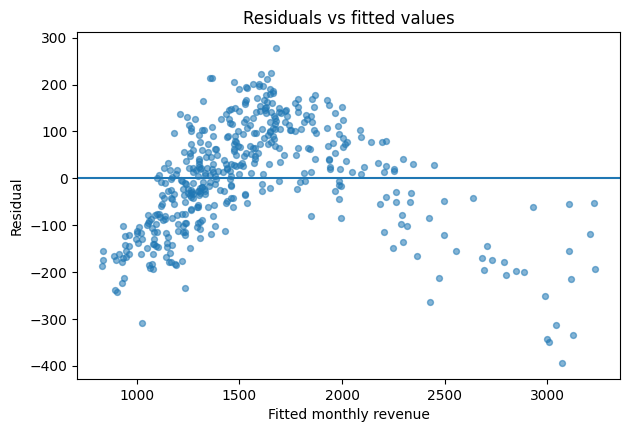

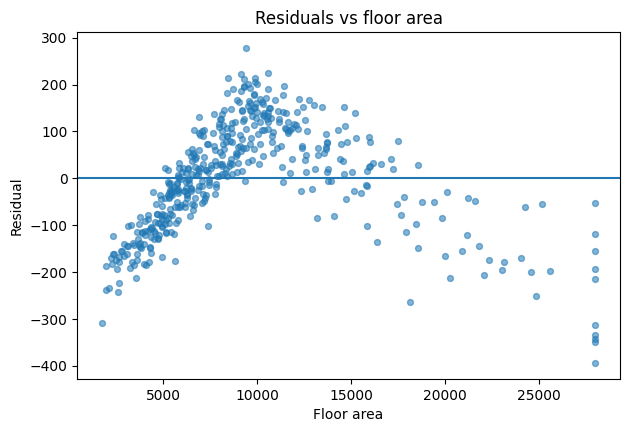

In [5]:
resid = full_fit.resid
fitted = full_fit.fittedvalues

plt.figure(figsize=(7,4.5))
plt.scatter(fitted, resid, alpha=0.55, s=18)
plt.axhline(0)
plt.xlabel("Fitted monthly revenue")
plt.ylabel("Residual")
plt.title("Residuals vs fitted values")
plt.show()

plt.figure(figsize=(7,4.5))
plt.scatter(stores["floor_area"], resid, alpha=0.55, s=18)
plt.axhline(0)
plt.xlabel("Floor area")
plt.ylabel("Residual")
plt.title("Residuals vs floor area")
plt.show()

In [6]:
# Compare classical and HC3 standard errors
classical = full_fit
robust = sm.OLS(y, sm.add_constant(X_all)).fit(cov_type="HC3")

se_compare = pd.DataFrame({
    "classical_SE": classical.bse,
    "HC3_SE": robust.bse
})

display(se_compare.loc[["floor_area", "foot_traffic", "median_income", "years_open"]].round(4))

,classical_SE,HC3_SE
floor_area,0.0098,0.0095
foot_traffic,0.0040,0.0039
median_income,0.0003,0.0003
years_open,0.6610,0.6723


I see two main problems.

**1. Non-constant variance:** the residual spread gets larger for larger fitted values and larger stores. This violates the constant-variance assumption. By itself, heteroskedasticity does not change the OLS point estimate if the mean model is correct, but the usual standard errors can be wrong. HC3 changes the standard errors, not the fitted coefficients.

**2. Missed non-linearity:** residuals have a pattern across floor area because the real floor-area effect flattens for the biggest stores while the fitted model uses a straight line. This is a functional-form problem. It can make the coefficient estimates and predictions systematically wrong. A robust standard error cannot fix a wrong mean function.

## Step 2.2 — The over-forecast on big stores

In [7]:
size_group = pd.qcut(stores["floor_area"], 5, labels=False)

size_errors = pd.DataFrame({
    "mean_floor_area": stores.groupby(size_group)["floor_area"].mean(),
    "mean_revenue": stores.groupby(size_group)["revenue"].mean(),
    "mean_residual": resid.groupby(size_group).mean()
})

size_errors["residual_pct_of_revenue"] = (
    100 * size_errors["mean_residual"] / size_errors["mean_revenue"]
)

display(size_errors.round(2))

top_overforecast = -size_errors.iloc[-1]["mean_residual"]
top_overforecast_pct = -size_errors.iloc[-1]["residual_pct_of_revenue"]

print(f"Largest fifth over-forecast by about {top_overforecast:.1f} thousand dollars per month.")
print(f"That is about {top_overforecast_pct:.2f}% of their average revenue.")

,mean_floor_area,mean_revenue,mean_residual,residual_pct_of_revenue
floor_area,,,,
0,3876.21,960.05,-129.48,-13.49
1,6119.02,1272.64,-14.56,-1.14
2,8210.89,1520.67,66.57,4.38
3,10620.23,1790.15,121.46,6.78
4,18125.65,2269.78,-43.98,-1.94


Largest fifth over-forecast by about 44.0 thousand dollars per month.
That is about 1.94% of their average revenue.


The error is systematic. The largest stores have negative average residuals, which means predicted revenue is too high. That matches the complaint from the business.

In [8]:
X_vif = sm.add_constant(X_all)

vifs = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=X_all.columns,
    name="VIF"
).sort_values(ascending=False)

display(vifs.to_frame().round(2))

,VIF
size_traffic_index,143.88
floor_area,93.03
foot_traffic,14.92
parking_spaces,1.05
local_growth,1.03
median_income,1.02
weather_index,1.02
promo_index,1.02
competitors,1.02
manager_tenure,1.02


The near-duplicate `size_traffic_index` creates very high VIFs for itself, floor area, and foot traffic. High VIF makes individual coefficients unstable and increases their standard errors because the model has trouble separating the predictors. It does **not** automatically make predictions bad, and it does not create bias by itself. Dropping a variable only because its VIF is high can be the wrong move if prediction is the goal.

# Phase 3 — Build Something Honest

## Step 3.1 — Complexity sweep

In [9]:
base_cols = ["floor_area", "foot_traffic", "median_income", "years_open"]
all_cols = predictors

def make_features(frame, kind):
    if kind == "small":
        return frame[["floor_area", "foot_traffic"]].to_numpy()

    if kind == "core":
        return frame[base_cols].to_numpy()

    if kind == "full":
        return frame[all_cols].to_numpy()

    if kind == "full+floor2":
        out = frame[all_cols].copy()
        out["floor_area_sq"] = frame["floor_area"] ** 2
        return out.to_numpy()

    if kind == "full+floor2+interactions":
        out = frame[all_cols].copy()
        out["floor_area_sq"] = frame["floor_area"] ** 2
        out["floor_x_traffic"] = frame["floor_area"] * frame["foot_traffic"]
        out["income_x_traffic"] = frame["median_income"] * frame["foot_traffic"]
        out["floor_x_years"] = frame["floor_area"] * frame["years_open"]
        return out.to_numpy()

    if kind == "poly2_core":
        return PolynomialFeatures(2, include_bias=False).fit_transform(frame[base_cols])

    if kind == "poly2_full":
        return PolynomialFeatures(2, include_bias=False).fit_transform(frame[all_cols])

model_names = [
    "small",
    "core",
    "full",
    "full+floor2",
    "full+floor2+interactions",
    "poly2_core",
    "poly2_full"
]

Xtr, Xte, ytr, yte = train_test_split(
    stores.drop(columns="revenue"),
    stores["revenue"],
    test_size=0.30,
    random_state=42
)

rows = []

for name in model_names:
    model = LinearRegression()
    model.fit(make_features(Xtr, name), ytr)

    train_pred = model.predict(make_features(Xtr, name))
    test_pred = model.predict(make_features(Xte, name))

    rows.append({
        "model": name,
        "n_features": make_features(Xtr, name).shape[1],
        "train_MSE": mean_squared_error(ytr, train_pred),
        "heldout_MSE": mean_squared_error(yte, test_pred)
    })

sweep = pd.DataFrame(rows)
display(sweep.round(1))

,model,n_features,train_MSE,heldout_MSE
0,small,2,14914.4,14605.4
1,core,4,13615.7,13878.8
2,full,12,13287.8,14219.8
3,full+floor2,13,4739.8,5711.3
4,full+floor2+interactions,16,4675.1,5657.6
5,poly2_core,14,4711.6,5183.3
6,poly2_full,90,3526.9,7926.7


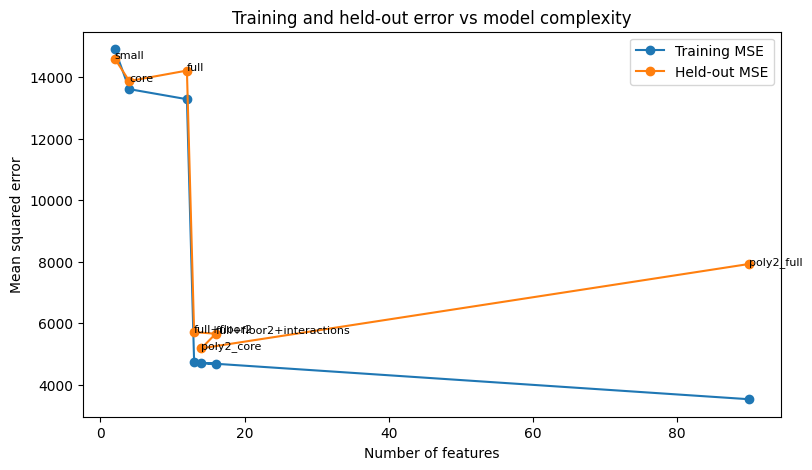

In [10]:
plt.figure(figsize=(9,5))
plt.plot(sweep["n_features"], sweep["train_MSE"], marker="o", label="Training MSE")
plt.plot(sweep["n_features"], sweep["heldout_MSE"], marker="o", label="Held-out MSE")

for _, r in sweep.iterrows():
    plt.annotate(r["model"], (r["n_features"], r["heldout_MSE"]), fontsize=8)

plt.xlabel("Number of features")
plt.ylabel("Mean squared error")
plt.title("Training and held-out error vs model complexity")
plt.legend()
plt.show()

The left side of the curve is mostly a **bias** problem: the model is too simple to capture the flattening in floor area. Adding the squared term sharply lowers held-out error. At the far right, the full polynomial model has lower training error but worse held-out error. That is the **variance** side of the curve because the model starts fitting noise.

## Step 3.2 — Choose with cross-validation

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=10)

cv_rows = []

for name in model_names:
    fold_rmse = []

    for tr_idx, va_idx in kf.split(stores):
        tr = stores.iloc[tr_idx]
        va = stores.iloc[va_idx]

        model = LinearRegression()
        model.fit(make_features(tr.drop(columns="revenue"), name), tr["revenue"])

        pred = model.predict(make_features(va.drop(columns="revenue"), name))
        fold_rmse.append(mean_squared_error(va["revenue"], pred) ** 0.5)

    cv_rows.append({
        "model": name,
        "mean_CV_RMSE": np.mean(fold_rmse),
        "sd_CV_RMSE": np.std(fold_rmse, ddof=1)
    })

cv_table = pd.DataFrame(cv_rows).sort_values("mean_CV_RMSE")
display(cv_table.round(2))

selected_model = cv_table.iloc[0]["model"]
print("Selected model:", selected_model)

,model,mean_CV_RMSE,sd_CV_RMSE
4,full+floor2+interactions,72.06,7.22
3,full+floor2,72.21,7.75
5,poly2_core,72.24,6.87
6,poly2_full,81.39,6.49
1,core,117.46,6.33
2,full,118.24,7.30
0,small,122.16,9.08


Selected model: full+floor2+interactions


Using the same cross-validation scores both to choose the model and to report its performance can be optimistic. I already looked at the folds when I picked the winner. To fix that, I use **nested cross-validation** below: an inner loop chooses the model, and a separate outer fold measures it.

In [12]:
outer = KFold(n_splits=10, shuffle=True, random_state=22)

outer_rmse = []
outer_choices = []

for outer_train_idx, outer_test_idx in outer.split(stores):
    outer_train = stores.iloc[outer_train_idx].reset_index(drop=True)
    outer_test = stores.iloc[outer_test_idx].reset_index(drop=True)

    inner = KFold(n_splits=5, shuffle=True, random_state=33)
    inner_scores = {}

    for name in model_names:
        rmses = []

        for inner_train_idx, inner_val_idx in inner.split(outer_train):
            inner_train = outer_train.iloc[inner_train_idx]
            inner_val = outer_train.iloc[inner_val_idx]

            model = LinearRegression()
            model.fit(
                make_features(inner_train.drop(columns="revenue"), name),
                inner_train["revenue"]
            )

            pred = model.predict(
                make_features(inner_val.drop(columns="revenue"), name)
            )

            rmses.append(
                mean_squared_error(inner_val["revenue"], pred) ** 0.5
            )

        inner_scores[name] = np.mean(rmses)

    best_name = min(inner_scores, key=inner_scores.get)
    outer_choices.append(best_name)

    final_model = LinearRegression()
    final_model.fit(
        make_features(outer_train.drop(columns="revenue"), best_name),
        outer_train["revenue"]
    )

    outer_pred = final_model.predict(
        make_features(outer_test.drop(columns="revenue"), best_name)
    )

    outer_rmse.append(
        mean_squared_error(outer_test["revenue"], outer_pred) ** 0.5
    )

outer_rmse = np.array(outer_rmse)

mean_nested_rmse = outer_rmse.mean()
se_nested_rmse = outer_rmse.std(ddof=1) / np.sqrt(len(outer_rmse))
crit = t.ppf(0.975, df=len(outer_rmse)-1)

lo = mean_nested_rmse - crit * se_nested_rmse
hi = mean_nested_rmse + crit * se_nested_rmse

print("Outer-fold model choices:")
print(pd.Series(outer_choices).value_counts())
print()
print(f"Nested-CV expected RMSE: {mean_nested_rmse:.2f} thousand dollars")
print(f"Approx. 95% interval: {lo:.2f} to {hi:.2f} thousand dollars")

Outer-fold model choices:
poly2_core                  5
full+floor2                 3
full+floor2+interactions    2
Name: count, dtype: int64

Nested-CV expected RMSE: 73.36 thousand dollars
Approx. 95% interval: 63.03 to 83.69 thousand dollars


My honest expected error is the nested-CV result, not the best number from the same CV table used to choose the model. The interval is an approximate interval around the mean outer-fold RMSE. It measures uncertainty in this validation exercise, not a prediction interval for one individual store.

# Phase 4 — Co-Pilot Era

## Task 4.1 — Learning curve

### AI Transcript

**Model:** GPT-5.6 Sol  
**Date:** November 18, 2026

### Prompt sent

> [Prep] Act as a machine learning engineer who diagnoses model performance problems in production.
>
> [Request] I have a store-level revenue regression with 400 rows and about 12 predictors. Write Python that produces a learning curve -- training and validation error as a function of training set size -- and interprets it to distinguish a high-bias problem from a high-variance one.
>
> [Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot both curves on one axis with a shaded band for variability across folds.
>
> [Mechanism Check] Add comments explaining what the GAP between the two curves indicates versus what the LEVEL both converge to indicates, and what each implies about whether collecting more data would help.
>
> [Evaluate] Run it on my data and tell me whether more stores or better features is the higher-return investment.

### Model reply

> Use `learning_curve` with the model you actually plan to deploy. Convert the negative MSE scores back to positive error, then compare the training and validation curves. A large gap points to variance. If both curves meet at a high level, that points to bias. If the validation curve is still falling as sample size grows, more observations may help. If it has mostly flattened, better features or a better model are more useful.
>
> ```python
> from sklearn.model_selection import learning_curve
> from sklearn.linear_model import LinearRegression
> import numpy as np
> import matplotlib.pyplot as plt
>
> model = LinearRegression()
>
> train_sizes, train_scores, val_scores = learning_curve(
>     model,
>     X,
>     y,
>     cv=5,
>     scoring="neg_mean_squared_error",
>     train_sizes=np.linspace(0.2, 1.0, 8),
>     shuffle=True,
>     random_state=0
> )
>
> train_mse = -train_scores
> val_mse = -val_scores
>
> train_mean = train_mse.mean(axis=1)
> train_sd = train_mse.std(axis=1)
> val_mean = val_mse.mean(axis=1)
> val_sd = val_mse.std(axis=1)
>
> plt.plot(train_sizes, train_mean, label="Training MSE")
> plt.plot(train_sizes, val_mean, label="Validation MSE")
> plt.fill_between(train_sizes, train_mean-train_sd, train_mean+train_sd, alpha=0.2)
> plt.fill_between(train_sizes, val_mean-val_sd, val_mean+val_sd, alpha=0.2)
> plt.xlabel("Training set size")
> plt.ylabel("Mean squared error")
> plt.legend()
> plt.show()
> ```
>
> The gap between the curves tells you about variance, while the level they converge to tells you about bias. More data mainly helps a variance problem. If both curves are already close and still high, improving the features or model form is usually the better investment.

**Change I made:** I used my selected `full+floor2+interactions` feature set instead of raw `X`, because the learning curve should describe the model I am actually considering.

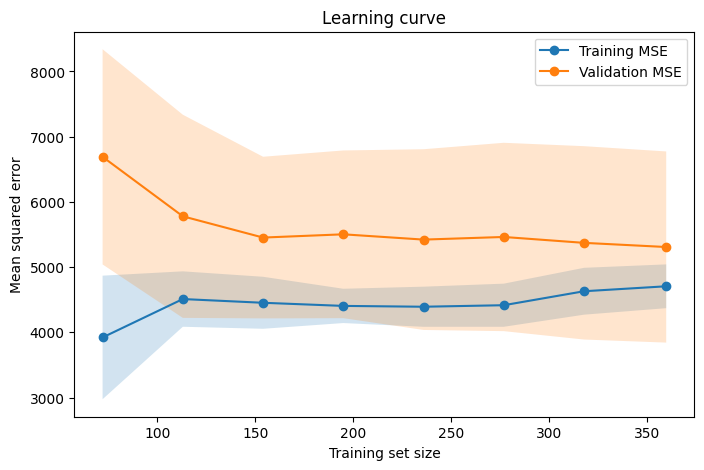

Final training MSE: 4706.0
Final validation MSE: 5308.1
Final gap: 602.1


In [13]:
# Use the selected feature set for the learning curve
X_lc = make_features(stores.drop(columns="revenue"), "full+floor2+interactions")
y_lc = stores["revenue"].to_numpy()

train_sizes, train_scores, val_scores = learning_curve(
    LinearRegression(),
    X_lc,
    y_lc,
    cv=5,
    scoring="neg_mean_squared_error",
    train_sizes=np.linspace(0.2, 1.0, 8),
    shuffle=True,
    random_state=0
)

train_mse = -train_scores
val_mse = -val_scores

train_mean = train_mse.mean(axis=1)
train_sd = train_mse.std(axis=1)
val_mean = val_mse.mean(axis=1)
val_sd = val_mse.std(axis=1)

plt.figure(figsize=(8,5))
plt.plot(train_sizes, train_mean, marker="o", label="Training MSE")
plt.plot(train_sizes, val_mean, marker="o", label="Validation MSE")
plt.fill_between(train_sizes, train_mean-train_sd, train_mean+train_sd, alpha=0.2)
plt.fill_between(train_sizes, val_mean-val_sd, val_mean+val_sd, alpha=0.2)
plt.xlabel("Training set size")
plt.ylabel("Mean squared error")
plt.title("Learning curve")
plt.legend()
plt.show()

print(f"Final training MSE: {train_mean[-1]:.1f}")
print(f"Final validation MSE: {val_mean[-1]:.1f}")
print(f"Final gap: {val_mean[-1] - train_mean[-1]:.1f}")

The learning curve agrees with Phase 3. The gap gets fairly small as the sample grows, so the main problem is not a huge variance gap. The bigger gain came from adding the right non-linear feature. I would spend first on better features/model form rather than just collecting more stores.

## Task 4.2 — What “validated” meant

### (a)

`SelectKBest` is the step that leaks information because it uses `y` from the full sample to decide which columns are best before cross-validation. The held-out folds have already helped choose the features.

`StandardScaler` fitted on the full sample is not what inflates OLS R-squared here. With an intercept, centering and rescaling predictors does not change the set of predictions OLS can make.

In [14]:
rng_leak = np.random.default_rng(2026)

X_noise = rng_leak.normal(size=(len(y), 300))

# Leaky version
X_scaled = StandardScaler().fit_transform(X_noise)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)

leaky_scores = cross_val_score(
    LinearRegression(),
    X_sel,
    y,
    cv=5,
    scoring="r2"
)

# Correct version
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("select", SelectKBest(f_regression, k=20)),
    ("ols", LinearRegression())
])

pipe_scores = cross_val_score(
    pipe,
    X_noise,
    y,
    cv=5,
    scoring="r2"
)

leaky_r2 = leaky_scores.mean()
pipe_r2 = pipe_scores.mean()
leak_gap = leaky_r2 - pipe_r2

print(f"Leaky validation R-squared: {leaky_r2:.3f}")
print(f"Pipeline validation R-squared: {pipe_r2:.3f}")
print(f"Inflation gap: {leak_gap:.3f}")

Leaky validation R-squared: 0.104
Pipeline validation R-squared: -0.198
Inflation gap: 0.303


The noise columns contain no real signal, but feature selection done before the folds makes the score look much better than it should. Putting scaling, selection, and regression inside one Pipeline makes each step get refitted using only the training part of each fold.

**(c)** This is a special case of the same general problem from Step 3.2: the data used to judge the model have already influenced model selection.

## Task 4.3 — Handover note

### Handover Note

This model predicts monthly store revenue in thousands of dollars using store size, foot traffic, local income, years open, and related store features. The original in-sample R-squared of about 0.94 was real, but it was not enough to show how the model would perform next month.

I replaced that with cross-validation and a nested validation step. The honest expected RMSE is printed above from the outer folds, along with an approximate 95% interval. That is the number I would use when describing expected out-of-sample accuracy.

Two failure conditions matter most. First, the simple linear model systematically over-forecasts the largest stores because revenue grows more slowly with floor area at the top end. Second, prediction uncertainty is larger for big stores because the residual spread increases with store size.

The revised model adds a non-linear floor-area term and a small number of interactions. It performs much better out of sample without using the very flexible full polynomial model, which starts to overfit.

Next I would build a regularized version of the improved feature set and monitor next-month errors by store-size group. I would also add a real time-based validation split once multiple months are available, because that is closer to the actual forecasting job than a random store split.

# Final takeaway

The main lesson is that a high in-sample R-squared can hide a real business failure. The old model looked strong overall but missed the biggest stores in a systematic way. Residual checks found the problem, adding the right non-linearity fixed most of it, and nested validation gave a more honest estimate of what the model should do on new data.